In [ ]:
import sys
from pathlib import Path

import pandas as pd

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root / "code"))

from paths import RAW_DATA_FILE, DATA_DIR

print(RAW_DATA_FILE)
print("Dataset exists:", RAW_DATA_FILE.is_file())

/workspaces/midterm-credit-default/data/default_of_credit_card_clients.xls
Dataset exists: True


In [2]:
excel = pd.ExcelFile(RAW_DATA_FILE, engine="calamine")
print("Sheets:", excel.sheet_names)

preview = pd.read_excel(excel, sheet_name=0, header=None, nrows=8)
display(preview.T)

Sheets: ['Data']


,0,1,2,3,4,5,6,7
0,NaN,ID,1,2,3,4,5,6
1,X1,LIMIT_BAL,20000,120000,90000,50000,50000,50000
2,X2,SEX,2,2,2,2,1,1
3,X3,EDUCATION,2,2,2,2,2,1
4,X4,MARRIAGE,1,2,2,1,1,2
5,X5,AGE,24,26,34,37,57,37
6,X6,PAY_0,2,-1,0,0,-1,0
7,X7,PAY_2,2,2,0,0,0,0
8,X8,PAY_3,-1,0,0,0,-1,0
9,X9,PAY_4,-1,0,0,0,0,0


## Load the data table

Use `header=1` because the descriptive column names are in the second Excel row (zero-based index 1). Check the shape, sample records, and column names to confirm the table was parsed correctly.

In [3]:
DF = pd.read_excel(excel, sheet_name=0, header=1)

print("Shape:", DF.shape)
display(DF.head())
print("Columns:", DF.columns.tolist())

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


## Normalize column names

# Remove surrounding whitespace, convert names to lowercase, and replace spaces with underscores. 
# This gives the target the name `default_payment_next_month` without changing any data values.

In [7]:


df = DF.copy(deep=True)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

## Inspect types, missing values, and uniqueness

Review inferred types, missing-value counts, and distinct-value counts. Integer storage does not imply a quantitative feature: some columns contain category codes. Count fully duplicated rows as an initial check; a unique ID can conceal otherwise identical records.

In [9]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   id                          30000 non-null  int64
 1   limit_bal                   30000 non-null  int64
 2   sex                         30000 non-null  int64
 3   education                   30000 non-null  int64
 4   marriage                    30000 non-null  int64
 5   age                         30000 non-null  int64
 6   pay_0                       30000 non-null  int64
 7   pay_2                       30000 non-null  int64
 8   pay_3                       30000 non-null  int64
 9   pay_4                       30000 non-null  int64
 10  pay_5                       30000 non-null  int64
 11  pay_6                       30000 non-null  int64
 12  bill_amt1                   30000 non-null  int64
 13  bill_amt2                   30000 non-null  int64
 14  bill_amt3        

In [10]:
display(
    pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "unique_values": df.nunique(),
    })
)


,dtype,missing,unique_values
id,int64,0,30000
limit_bal,int64,0,81
sex,int64,0,2
education,int64,0,7
marriage,int64,0,4
age,int64,0,56
pay_0,int64,0,11
pay_2,int64,0,11
pay_3,int64,0,11
pay_4,int64,0,11


In [11]:

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Check duplicate records excluding ID

Identify records with identical feature values and target labels, regardless of their unique identifiers.

This check helps detect potentially duplicated observations that would be hidden by the unique `id` column.

Identical records do not necessarily represent data errors: different clients can share the same characteristics and outcome. Therefore, duplicates are inspected but not automatically removed.

In [17]:
print("Duplicates excluding ID:", df.drop(columns="id").duplicated().sum())

Duplicates excluding ID: 35


## Inspect categorical codes and target balance

Count the observed values of `sex`, `education`, `marriage`, and the target, including missing values if present. These counts help identify codes that need interpretation against the source documentation. Target proportions show class balance; no recoding or resampling is performed here.

In [18]:
for col in ["sex", "education", "marriage", "default_payment_next_month"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())

print("\nTarget proportions:")
print(df["default_payment_next_month"].value_counts(normalize=True))


sex
sex
1    11888
2    18112
Name: count, dtype: int64

education
education
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

marriage
marriage
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

default_payment_next_month
default_payment_next_month
0    23364
1     6636
Name: count, dtype: int64

Target proportions:
default_payment_next_month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


## Describe quantitative variables

Inspect central tendency, spread, and tail percentiles for credit limits, age, statement balances, and payments. 

In [21]:
df.columns

Index(['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0',
       'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'default_payment_next_month'],
      dtype='str')

In [20]:
data_before_descriptive_eda = df.copy(deep=True)

numeric_cols = [
    "limit_bal", "age",
    *[f"bill_amt{i}" for i in range(1, 7)],
    *[f"pay_amt{i}" for i in range(1, 7)],
]

display(df[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)


,count,mean,std,min,1%,25%,50%,75%,99%,max
limit_bal,30000.0,167484.322667,129747.661567,10000.0,10000.00,50000.00,140000.0,240000.00,500000.00,1000000.0
age,30000.0,35.485500,9.217904,21.0,22.00,28.00,34.0,41.00,60.00,79.0
bill_amt1,30000.0,51223.330900,73635.860576,-165580.0,-81.00,3558.75,22381.5,67091.00,350110.68,964511.0
bill_amt2,30000.0,49179.075167,71173.768783,-69777.0,-200.00,2984.75,21200.0,64006.25,337495.28,983931.0
bill_amt3,30000.0,47013.154800,69349.387427,-157264.0,-200.00,2666.25,20088.5,60164.75,325030.39,1664089.0
bill_amt4,30000.0,43262.948967,64332.856134,-170000.0,-212.02,2326.75,19052.0,54506.00,304997.27,891586.0
bill_amt5,30000.0,40311.400967,60797.155770,-81334.0,-232.01,1763.00,18104.5,50190.50,285868.33,927171.0
bill_amt6,30000.0,38871.760400,59554.107537,-339603.0,-331.03,1256.00,17071.0,49198.25,279505.06,961664.0
pay_amt1,30000.0,5663.580500,16563.280354,0.0,0.00,1000.00,2100.0,5006.00,66522.18,873552.0
pay_amt2,30000.0,5921.163500,23040.870402,0.0,0.00,833.00,2009.0,5000.00,76651.02,1684259.0


## Inspect repayment status frequencies

Count how many clients have each repayment status code for each month.

`pay_0` refers to September 2005, followed by `pay_2` (August) through `pay_6` (April). There is no `pay_1`.

Repayment status codes:
- `-2`: undocumented.
- `-1`: payment made on time.
- `0`: undocumented.
- `1` to `8`: number of months of payment delay.
- `9`: payment delay of nine months or more (not observed in dataset).

Each row represents a repayment status code, each column represents a month, and each cell contains the number of clients with that status in that month.

Verify that frequencies in each column sum to 30,000, accounting for every client.

In [34]:
repayment_cols = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]
repayment_counts = pd.DataFrame({
    col: df[col].value_counts().sort_index()
    for col in repayment_cols
}).fillna(0).astype(int)

display(repayment_counts)
assert repayment_counts.sum().eq(len(df)).all()
print("Records accounted for in each repayment column:")
print(repayment_counts.sum())


,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


Records accounted for in each repayment column:
pay_0    30000
pay_2    30000
pay_3    30000
pay_4    30000
pay_5    30000
pay_6    30000
dtype: int64


Repayment status distributions are dominated by codes `0`, `-1`, and `-2`. The undocumented codes `0` and `-2` occur frequently and should not be discarded. Code `1` is substantially more frequent in September than in previous months, while codes `4–8` are rare and code `9` is absent.

These findings support preserving distinct repayment status categories during preprocessing. Their relationship with default risk requires separate analysis of default rates by status code.

## Inspect negative and zero monetary values

Count negative and zero values in credit limits (`limit_bal`), monthly bill amounts (`bill_amt1`–`bill_amt6`), and payment amounts (`pay_amt1`–`pay_amt6`) to identify potential data quality issues and understand financial distributions.

**Findings:**

- `limit_bal` contains no negative or zero values.
- Bill amounts contain some negative values (590–688 per month), whose meaning is not documented. Zero balances are also common.
- Payment amounts are never negative, but zero payments are frequent (approximately 17–24% of records per month).

**Conclusion:** These values are not necessarily data errors. Preserve them rather than removing or imputing them without supporting evidence.

In [36]:
bill_cols = [f"bill_amt{i}" for i in range(1, 7)]
payment_cols = [f"pay_amt{i}" for i in range(1, 7)]
amount_cols = ["limit_bal", *bill_cols, *payment_cols]

display(pd.DataFrame({
    "negative_count": df[amount_cols].lt(0).sum(),
    "zero_count": df[amount_cols].eq(0).sum(),
}))


,negative_count,zero_count
limit_bal,0,0
bill_amt1,590,2008
bill_amt2,669,2506
bill_amt3,655,2870
bill_amt4,675,3195
bill_amt5,655,3506
bill_amt6,688,4020
pay_amt1,0,5249
pay_amt2,0,5396
pay_amt3,0,5968


## Inspect the age distribution

Count clients at each observed age. This describes sample coverage; it does not establish a relationship between age and default.

<Axes: >

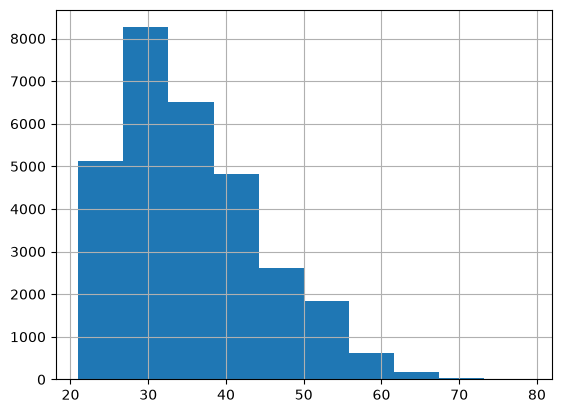

In [38]:
# display(
#     df["age"].value_counts().sort_index()
#     .rename_axis("age").to_frame("count")
    
# )

(df["age"].hist())


### Numerical distributions: findings

Financial variables exhibit strongly right-skewed distributions, with many relatively small amounts and a few extreme values. Bill amounts also include negative values.

For example, `bill_amt1` has a mean of 51,223 and a median of 22,382, indicating substantial positive skewness. Monthly bill distributions show similar patterns, suggesting potentially redundant information.

These findings support scaling numerical features for Logistic Regression, while highlighting that StandardScaler is sensitive to extreme values.

No observations are removed or transformed solely based on these distributions.

In [40]:
bill_amounts = [col for col in df.columns if col.startswith('bill')]
df[bill_amounts].describe().round().rename(index={'50%': 'median'})

,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6
count,30000.0,30000.0,30000.0,30000.0,30000.0,30000.0
mean,51223.0,49179.0,47013.0,43263.0,40311.0,38872.0
std,73636.0,71174.0,69349.0,64333.0,60797.0,59554.0
min,-165580.0,-69777.0,-157264.0,-170000.0,-81334.0,-339603.0
25%,3559.0,2985.0,2666.0,2327.0,1763.0,1256.0
median,22382.0,21200.0,20088.0,19052.0,18104.0,17071.0
75%,67091.0,64006.0,60165.0,54506.0,50190.0,49198.0
max,964511.0,983931.0,1664089.0,891586.0,927171.0,961664.0


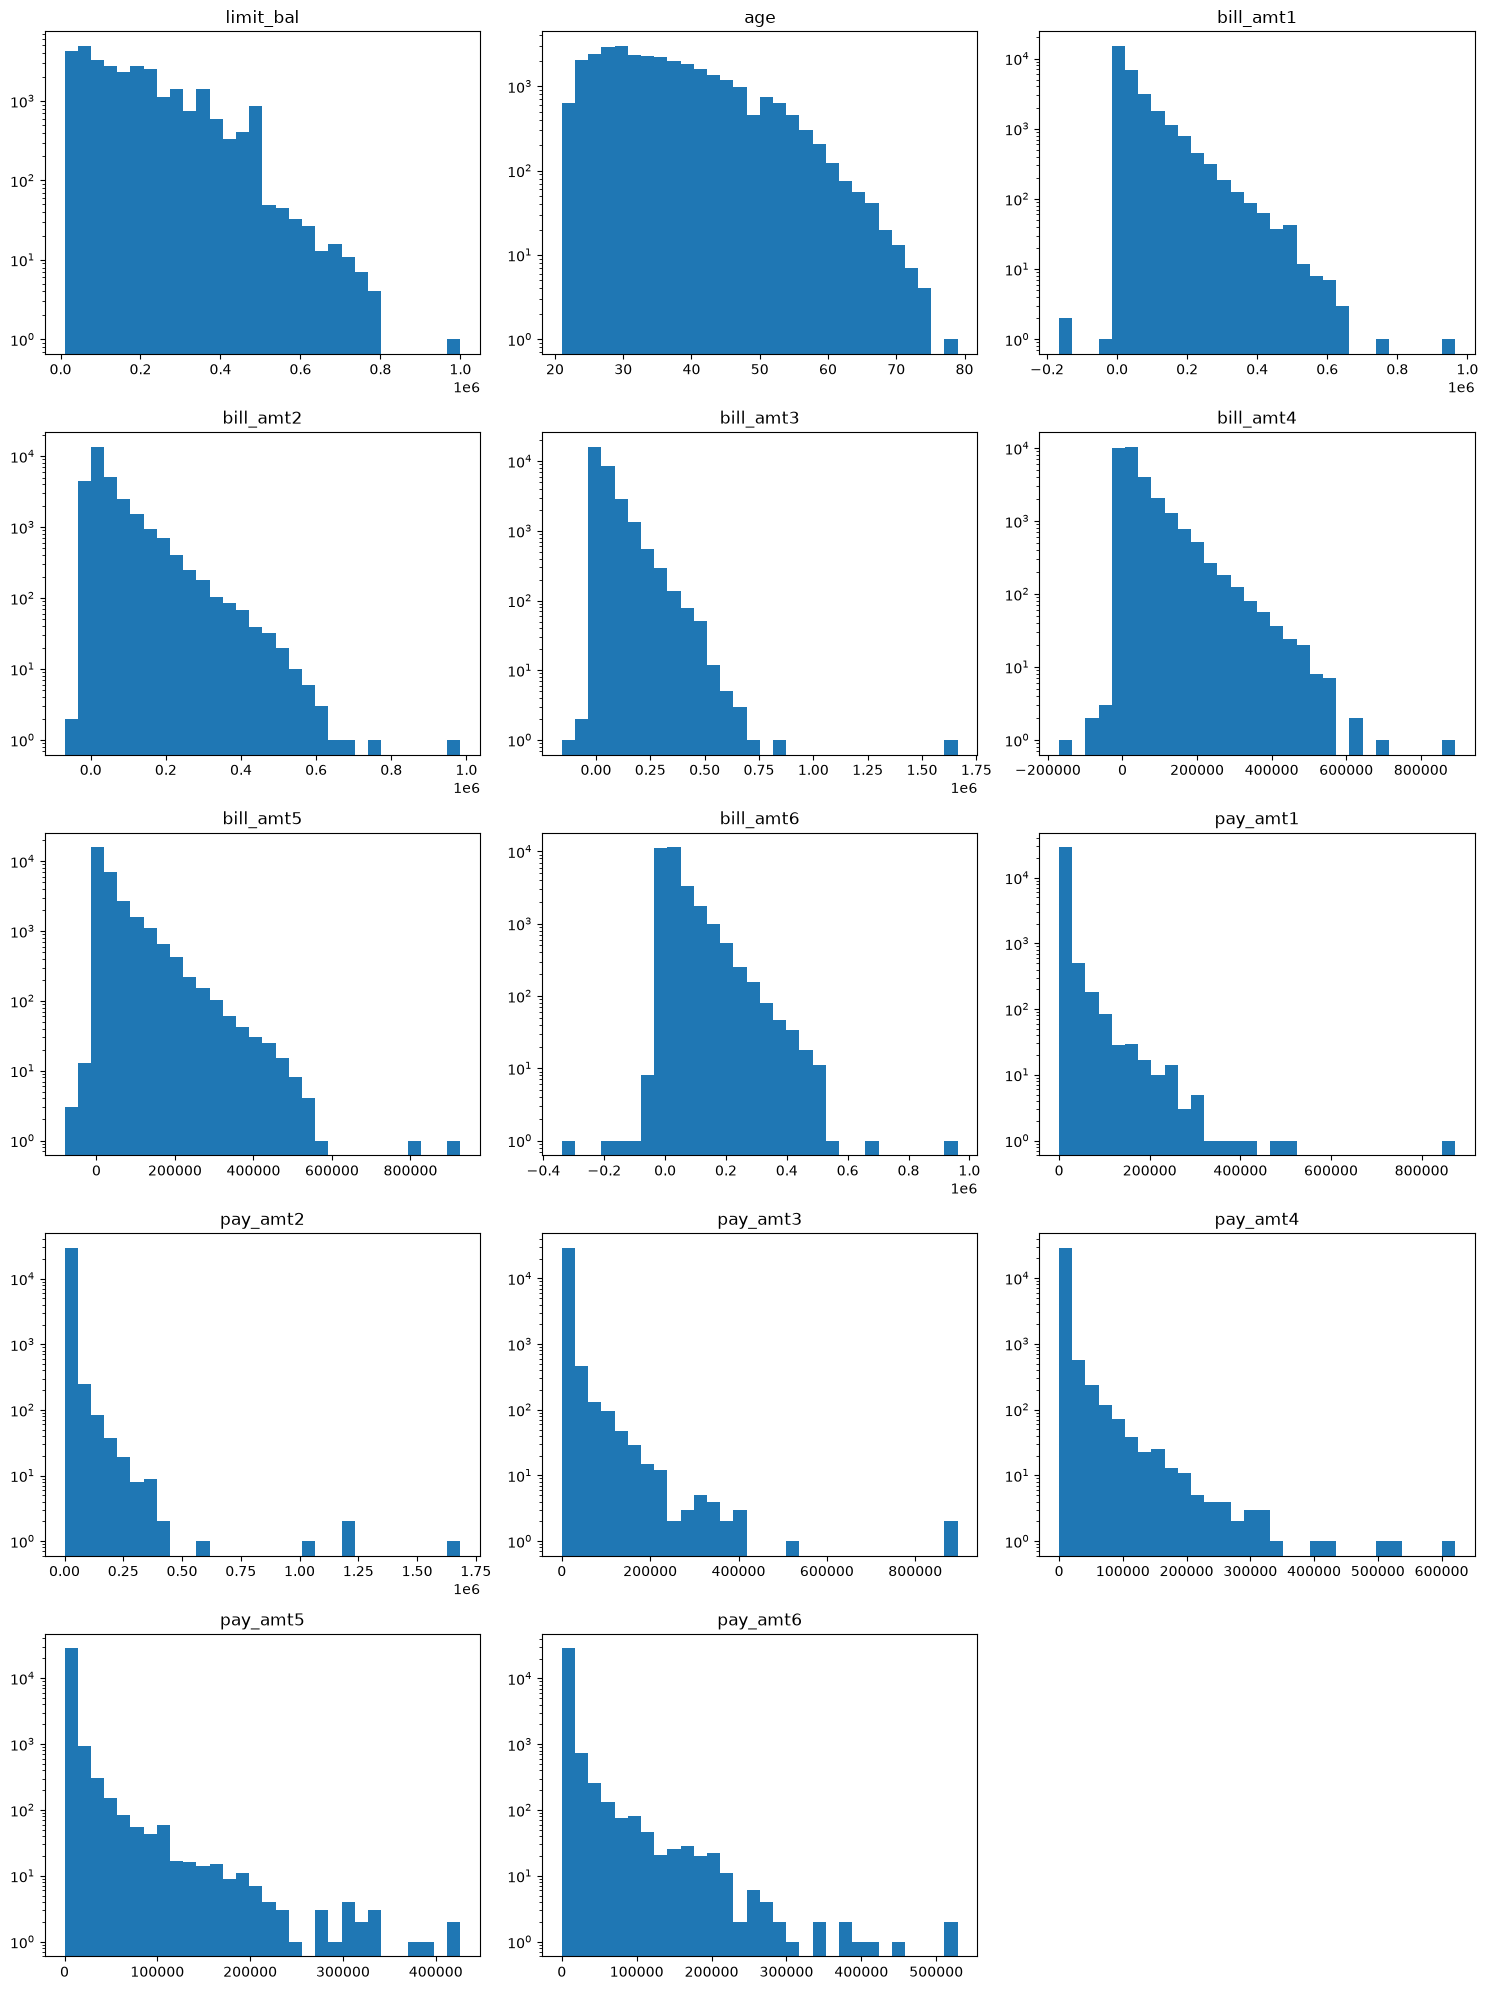

In [41]:
import math
import matplotlib.pyplot as plt

n = len(numeric_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(col)
    ax.set_yscale('log')

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Inspect repeated feature profiles

Group by all 23 predictors, excluding both ID and target. A repeated profile has at least two records. Concordant groups share one target value; discordant groups contain both outcomes. Counts of groups, participating records, and excess records describe different quantities. Identical observed profiles do not prove that records belong to the same person. Retain all records and use these findings when designing the split.

In [ ]:
target = "default_payment_next_month"
feature_cols = df.columns.drop(["id", target]).tolist()
profile_groups = (
    df.groupby(feature_cols, dropna=False)[target]
    .agg(record_count="size", target_values="nunique", default_count="sum")
    .reset_index()
)
repeated_profiles = profile_groups.loc[profile_groups["record_count"].gt(1)].copy()
repeated_profiles["target_agreement"] = repeated_profiles["target_values"].map({
    1: "concordant", 2: "discordant",
})
profile_summary = (
    repeated_profiles.groupby("target_agreement")
    .agg(profile_groups=("record_count", "size"), records=("record_count", "sum"))
    .reindex(["concordant", "discordant"], fill_value=0)
)
profile_summary["excess_records"] = profile_summary["records"] - profile_summary["profile_groups"]
display(profile_summary)
display(repeated_profiles)
assert profile_groups["record_count"].sum() == len(df)


,profile_groups,records,excess_records
target_agreement,,,
concordant,31,62,31
discordant,21,46,25


,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,pay_5,...,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,record_count,target_values,default_count,target_agreement
1022,20000,1,2,2,24,2,2,4,4,4,...,0,0,0,0,0,0,3,2,2,discordant
5158,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
6061,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
6801,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
9373,80000,1,1,2,37,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
9713,80000,1,3,2,27,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
10045,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
10333,80000,2,2,2,25,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
10618,80000,2,3,1,42,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
11076,90000,2,1,2,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant


### Investigate repeated profiles with zero financial amounts

Check whether repeated feature profiles have zero bill and payment amounts across all six months.

Cross-tabulate these profiles by target agreement:

- **Concordant:** identical predictors and identical target.
- **Discordant:** identical predictors but different target values.

Each cell counts records belonging to repeated profiles, not the number of distinct profiles.

**Purpose:** understand whether repeated profiles are concentrated among clients with zero financial activity and whether identical observed characteristics can lead to different default outcomes.

Repeated profiles are retained because identical observed data do not prove duplicate client records.

In [44]:
repeated_profiles["all_amounts_zero"] = (
    repeated_profiles[bill_cols + payment_cols]
    .eq(0)
    .all(axis=1)
)

pd.crosstab(
    repeated_profiles["target_agreement"],
    repeated_profiles["all_amounts_zero"],
    values=repeated_profiles["record_count"],
    aggfunc="sum"
).fillna(0)

all_amounts_zero,False,True
target_agreement,,
concordant,8,54
discordant,3,43


## Default rate by repayment status

Analyze relationship between September 2005 repayment status (`pay_0`) and default outcome.

For each repayment code, calculate:

- **count:** number of clients with that status.
- **default_rate:** proportion of clients who defaulted.

**Purpose:** determine whether repayment status is associated with default risk and whether different status codes exhibit different default rates.

Data show tha default rate does not increase monotonically with 

In [51]:
default_by_status = (
    df.groupby("pay_0")["default_payment_next_month"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "default_rate"})
)

display(default_by_status.sort_values('default_rate',ascending=False))

,count,default_rate
pay_0,,
7,9,0.777778
3,322,0.757764
2,2667,0.691414
4,76,0.684211
8,19,0.578947
6,11,0.545455
5,26,0.500000
1,3688,0.339479
-1,5686,0.167781


Default rates vary substantially across repayment codes:

Codes -2, -1, 0: approximately 13–17%.
Code 1: 33.9%.
Code 2: 69.1%.
Code 3: 75.8%.
Code 7: highest observed default rate (77.8%), but only 9 clients.

Default rate increases from codes 1 to 3, but the relationship is not monotonic across all delay codes. Higher codes have very small sample sizes, making their estimated rates unstable.

## Default rate by demographic categories

Calculate default rate for each observed value of `sex`, `education`, and `marriage`.

For each category:

- **count:** number of clients.
- **default_rate:** proportion of clients who defaulted.

**Purpose:** identify associations between demographic categories and default, and check whether rare or undocumented categories have sufficient observations for meaningful interpretation.

Differences in default rates are descriptive associations, not evidence of causality.


In [47]:
for col in ["sex", "education", "marriage"]:
    print(f"\n{col}")

    result = (
        df.groupby(col)["default_payment_next_month"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "default_rate"})
    )

    display(result)


sex


,count,default_rate
sex,,
1,11888,0.241672
2,18112,0.207763



education


,count,default_rate
education,,
0,14,0.000000
1,10585,0.192348
2,14030,0.237349
3,4917,0.251576
4,123,0.056911
5,280,0.064286
6,51,0.156863



marriage


,count,default_rate
marriage,,
0,54,0.092593
1,13659,0.234717
2,15964,0.209283
3,323,0.260062


sex: default rates differ by approximately 3.4 percentage points.

education: 19.2% for graduate school (1), 23.7% for university (2), and 25.2% for high school (3).

marriage: 23.5% for married clients versus 20.9% for single clients.


## Default rate by credit limit and age

Divide `limit_bal` and `age` into five quantile-based groups using `pd.qcut()`.

For each group, calculate:
- **count:** number of clients.
- **default_rate:** proportion of clients who defaulted.

**Purpose:** examine how default risk varies across credit limits and age ranges, including possible non-linear relationships.

In [52]:
for col in ["limit_bal", "age"]:
    groups = pd.qcut(df[col], q=5, duplicates="drop")

    result = (
        df.groupby(groups, observed=True)["default_payment_next_month"]
        .agg(count="size", default_rate="mean")
    )

    print(f"\n{col}")
    display(result)


limit_bal


,count,default_rate
limit_bal,,
"(9999.999, 50000.0]",7676,0.317874
"(50000.0, 100000.0]",4822,0.257984
"(100000.0, 180000.0]",6123,0.198595
"(180000.0, 270000.0]",5421,0.168604
"(270000.0, 1000000.0]",5958,0.137966



age


,count,default_rate
age,,
"(20.999, 27.0]",6604,0.241975
"(27.0, 31.0]",5626,0.195876
"(31.0, 37.0]",6728,0.205113
"(37.0, 43.0]",5056,0.217563
"(43.0, 79.0]",5986,0.243234


Credit limit (limit_bal)

Default rate decreases consistently as credit limit increases, from 31.8% in the lowest group to 13.8% in the highest group.

Age

Default rate follows an approximately U-shaped pattern: it is higher among younger (24.2%) and older clients (24.3%), with the lowest rate among clients aged approximately 27–31 (19.6%).

In [54]:
from code.paths import DATA_DIR

ModuleNotFoundError: No module named 'code.paths'; 'code' is not a package

In [ ]:
df.to_parquet(Data)

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
